# Лабораторная 2. Интервенции и выбор ветви графа гиперупругости
Синтетика и реальные измерения Treloar; зануление напряжения; Метрополис — Хастингс; Колмогоров — Смирнов; удаление или сохранение квадратичной ветви.

Запуск: Python 3.10+, `pip install numpy scipy pandas matplotlib jupyter`.

## 1. Уравнение и границы исследования


Рассматриваем медленную деформацию гиперупругого материала, для которого напряжения определяются запасённой упругой энергией. Если пренебречь инерцией и объёмными силами, уравнение равновесия имеет вид

$$
\mathrm{Div}\,\mathbf P=0.
$$

Здесь $\mathbf P$ — первый тензор напряжений Пиолы — Кирхгофа, а $\mathrm{Div}$ — дивергенция по координатам исходной конфигурации.

Деформация описывается градиентом

$$
F=I+\nabla_X u,
$$

где $u(X)$ — поле перемещений, а $I$ — единичная матрица. Для гиперупругого материала напряжение связано с производной плотности энергии $W$ по $F$. В модели без дополнительного ограничения несжимаемости эта связь записывается как

$$
\mathbf P=\frac{\partial W}{\partial F}.
$$

### Однородное одноосное растяжение

В этой работе рассматриваем однородное растяжение вдоль одной оси. Его величину характеризует коэффициент растяжения

$$
\lambda=\frac{\text{текущая длина}}{\text{исходная длина}}.
$$

Предполагаем, что материал несжимаем: его объём при деформации сохраняется. Поэтому при растяжении вдоль первой оси он сужается в двух поперечных направлениях. При одинаковом поперечном сужении главные растяжения равны

$$
\lambda_1=\lambda,\qquad
\lambda_2=\lambda_3=\lambda^{-1/2}.
$$

Действительно, их произведение равно единице:

$$
J=\det F=\lambda_1\lambda_2\lambda_3=1.
$$

Следовательно,

$$
F=\mathrm{diag}\left(\lambda,\lambda^{-1/2},\lambda^{-1/2}\right).
$$

При однородной деформации $F$ и напряжение постоянны по пространству, поэтому уравнение равновесия выполняется автоматически. Это позволяет исследовать закон материала по зависимости напряжения от растяжения без пространственного численного решателя.

### Инвариант деформации и величина $s$

Введём правый тензор деформации Коши — Грина:

$$
C=F^{\mathsf T}F
=\mathrm{diag}\left(\lambda^2,\lambda^{-1},\lambda^{-1}\right).
$$

Его первый инвариант — след, то есть сумма диагональных элементов:

$$
I_1=\mathrm{tr}\,C=\lambda^2+\frac{2}{\lambda}.
$$

Это скалярная характеристика деформации, не зависящая от ориентации системы координат. В недеформированном состоянии $\lambda=1$ и $I_1=3$. Поэтому удобно ввести обозначение

$$
s=I_1-3=\lambda^2+\frac{2}{\lambda}-3.
$$

Величина $s$ равна нулю без деформации. Она безразмерна и не является напряжением.

### Модель энергии Yeoh второго порядка

Чтобы связать деформацию с напряжением, необходимо выбрать закон материала. Используем модель Yeoh второго порядка:

$$
W=C_{10}(I_1-3)+C_{20}(I_1-3)^2
=C_{10}s+C_{20}s^2.
$$

Здесь $W$ — упругая энергия на единицу исходного объёма, а $C_{10}$ и $C_{20}$ — неизвестные параметры, определяемые по данным:

- $C_{10}$ задаёт базовую жёсткость материала;
- $C_{20}$ описывает дополнительное изменение жёсткости при увеличении деформации.

Оба коэффициента имеют размерность напряжения; в работе используются MPa.

Форма $W$ является **модельным предположением**, а не следствием уравнения равновесия.

### Вычисление наблюдаемого напряжения

После подстановки выбранной деформации энергия становится функцией одного растяжения:

$$
\widehat W(\lambda)
=C_{10}s(\lambda)+C_{20}s(\lambda)^2.
$$

При свободных от нагрузки боковых поверхностях продольное номинальное напряжение равно

$$
P_{11}(\lambda)=\frac{\mathrm d\widehat W}{\mathrm d\lambda}
=2\left(\lambda-\lambda^{-2}\right)
\left[C_{10}+2C_{20}s(\lambda)\right].
$$

В полной несжимаемой постановке тензор напряжений дополнительно содержит множитель давления, обеспечивающий ограничение $J=1$. В приведённой одноосной формуле он уже исключён с учётом условий на боковых поверхностях.

В ноутбуке напряжение вычисляется распространением производных по вычислительному графу энергии. Проверяемый структурный элемент — ветвь $C_{20}s^2$. Её удаление оставляет модель $W=C_{10}s$, причём зависимость напряжения от растяжения и в этой сокращённой модели остаётся нелинейной.

Удаляемый элемент — ребро $C_{20}s^2\to W$ и ставшие ненужными вершины. Общая вершина s сохраняется. C10 защищён как базовая жёсткость. Граф ниже действительно используется для вычислений: значения и производные распространяются по операциям.

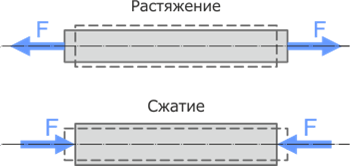

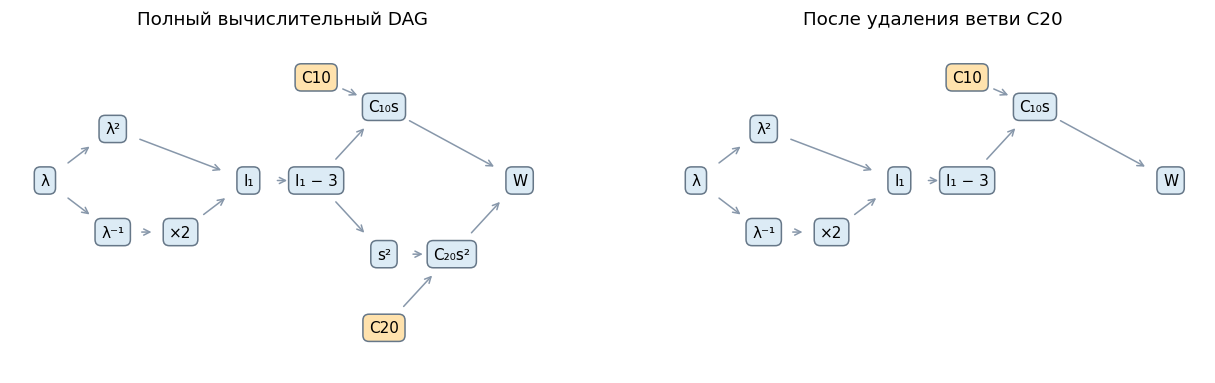

In [ ]:
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from scipy import stats
import time
START=time.perf_counter()
plt.rcParams.update({'figure.dpi':110, 'axes.grid':True, 'grid.alpha':.2})
# Узел: операция, входы. d — производная по lambda; forward-mode AD.
def make_graph(reduced=False):
    g={'l':('input',()), 'a':('pow',('l',2)), 'b':('pow',('l',-1)),
       'c':('scale',('b',2)), 'I1':('add',('a','c')), 's':('offset',('I1',-3)),
       'C10':('param',(0,)), 't1':('mul',('C10','s'))}
    if reduced: g['W']=('copy',('t1',))
    else: g.update({'s2':('pow',('s',2)), 'C20':('param',(1,)),
                   't2':('mul',('C20','s2')), 'W':('add',('t1','t2'))})
    return g
G=make_graph(); G1=make_graph(True)
def evaluate(g, lam, theta):
    out={}
    for name,(op,args) in g.items():
        if op=='input': v,d=np.asarray(lam),np.ones_like(lam)
        elif op=='param': v,d=theta[args[0]],0.
        elif op=='pow':
            x,dx=out[args[0]]; p=args[1]; v,d=x**p,p*x**(p-1)*dx
        elif op=='scale':
            x,dx=out[args[0]]; v,d=args[1]*x,args[1]*dx
        elif op=='offset':
            x,dx=out[args[0]]; v,d=x+args[1],dx
        elif op=='copy': v,d=out[args[0]]
        else:
            x,dx=out[args[0]]; y,dy=out[args[1]]
            v,d=(x+y,dx+dy) if op=='add' else (x*y,dx*y+x*dy)
        out[name]=(v,d)
    return out['W'][1]
def design(x,reduced=False):
    g=G1 if reduced else G
    return np.column_stack([evaluate(g,x,t) for t in ([(1.,0.)] if reduced else [(1.,0.),(0.,1.)])])
def draw_graph(ax,reduced=False):
    g=make_graph(reduced)
    pos={'l':(0,2),'a':(1,2.7),'b':(1,1.3),'c':(2,1.3),'I1':(3,2),'s':(4,2),
         'C10':(4,3.4),'t1':(5,3),'s2':(5,1),'C20':(5,0),'t2':(6,1),'W':(7,2)}
    labels={'l':'λ','a':'λ²','b':'λ⁻¹','c':'×2','I1':'I₁','s':'I₁ − 3','s2':'s²','t1':'C₁₀s','t2':'C₂₀s²'}
    for n,(op,args) in g.items():
        for p in args:
            if isinstance(p,str) and p in g:
                ax.annotate('',xy=pos[n],xytext=pos[p],arrowprops={'arrowstyle':'->','color':'#8797aa','shrinkA':19,'shrinkB':19})
    for n in g:
        ax.text(*pos[n],labels.get(n,n),ha='center',va='center',bbox={'boxstyle':'round,pad=.4','fc':'#ffe2ad' if n.startswith('C') else '#dcebf5','ec':'#678'})
    ax.set(xlim=(-.5,7.5),ylim=(-.6,4));ax.axis('off')
fig,axs=plt.subplots(1,2,figsize=(14,4));draw_graph(axs[0]);draw_graph(axs[1],True)
axs[0].set_title('Полный вычислительный DAG');axs[1].set_title('После удаления ветви C20');plt.show()
xcheck=np.linspace(1.1,5,20);h=1e-6;t=np.array([.2,.001])
f=lambda x:t[0]*(x*x+2/x-3)+t[1]*(x*x+2/x-3)**2
assert np.allclose(evaluate(G,xcheck,t),(f(xcheck+h)-f(xcheck-h))/(2*h),rtol=1e-6)


## 2. Данные и заранее заданный протокол
Реальные данные: Treloar (1944), одноосное растяжение при 20°C, цифровая таблица CANN: лист 1, столбцы A (растяжение) и C (номинальное напряжение, уже MPa). Берём диапазон 1 < λ ≤ 6 без интерполяции. Числа встроены ниже.
Источник: https://github.com/LivingMatterLab/CANN/blob/a639ea97acfa1064005381645c1a2fda74bcbfcd/GICANN/input/CANNsRUBBERdata.xlsx

Два синтетических контроля: C20=0 (лишняя ветвь) и C20=0.002 MPa (нужная ветвь). 30 точек и нормальный шум σ=0.03 MPa. Каждая четвёртая точка — неизменяемая проверочная выборка. Для реальных данных σ=0.08 MPa — рабочий масштаб ошибки модели, не паспортная погрешность прибора.

Интервенция: зануление напряжений в доле q обучающих точек. Маски вложенные, одна фиксированная перестановка; q=0, 0.25, 0.5. Это повреждение измерений, а не физическое изменение материала. Нулевые точки не удаляются. Для простоты исследуется одна маска; вывод не усреднён по всем способам зануления.

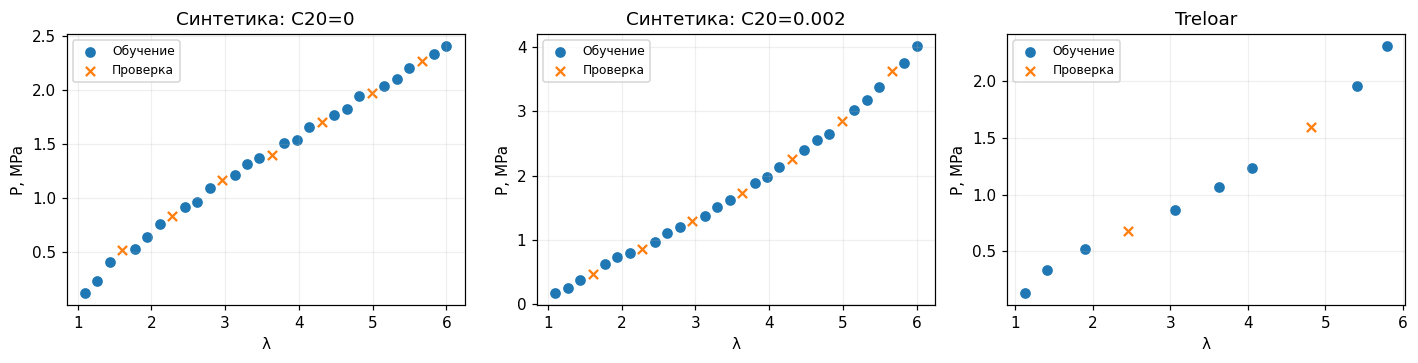

Размеры наборов: {'Синтетика: C20=0': 30, 'Синтетика: C20=0.002': 30, 'Treloar': 10}


In [ ]:
real=np.array([[1.12885809997723, 0.13605622522522354], [1.41047907112889, 0.3339561891891877], [1.8940384427749, 0.5194874054054027], [2.45295475981396, 0.6802811261261245], [3.06286792207369, 0.8658123423423396], [3.62246723257553, 1.0637123063063016], [4.05525742348847, 1.2368747747747637], [4.81998243731095, 1.5955684594594526], [5.40781214427424, 1.9542621441441415], [5.79324812176797, 2.3005870810810753]])
rng=np.random.default_rng(42); x=np.linspace(1.1,6,30)
datasets={'Синтетика: C20=0':(x,design(x)@np.array([.2,0])+rng.normal(0,.03,len(x)),.03),
'Синтетика: C20=0.002':(x,design(x)@np.array([.2,.002])+rng.normal(0,.03,len(x)),.03),
'Treloar':(real[:,0],real[:,1],.08)}
splits={};masks={}
fig,axs=plt.subplots(1,3,figsize=(13,3.4))
for ax,(name,(x,y,sig)) in zip(axs,datasets.items()):
    test=np.arange(len(x))%4==3;train=~test;splits[name]=(train,test)
    masks[name]=np.random.default_rng(2026).permutation(train.sum())
    ax.scatter(x[train],y[train],label='Обучение');ax.scatter(x[test],y[test],marker='x',label='Проверка')
    ax.set(title=name,xlabel='λ',ylabel='P, MPa');ax.legend(fontsize=8)
plt.tight_layout();plt.show()
print('Размеры наборов:',{k:len(v[0]) for k,v in datasets.items()})


## 3. Распределение параметров и Метрополис — Хастингс
Используем $\pi(\theta\mid D)\propto \exp[-\frac12\sum((A\theta-y)/\sigma)^2]p(\theta)$, независимый нормальный prior: $C_{10}\sim N(0.2,0.3^2)$, $C_{20}\sim N(0,0.02^2)$ (MPa). Это линейно-гауссовая задача: точные среднее и ковариация доступны для проверки MH. Отрицательные значения не обрезаем; физическую допустимость итогового закона проверяем отдельно на изученном диапазоне.

MH: симметричное нормальное случайное блуждание с ковариацией, пропорциональной аналитической апостериорной; принимаем предложение с вероятностью min(1, exp(logπ(new)−logπ(old))). Четыре цепи, 1000 шагов прогрева, 4000 сохраняемых состояний. Повторы при отклонении сохраняются. Аналитические выборки не подменяют MH.

Контроль: split-Rhat (обычный, не rank-normalized), ESS по начальной положительной последовательности автокорреляций, сравнение среднего MH с точным. Для этой гладкой нормальной задачи этого достаточно как учебной диагностики.

              Данные    q  Принятие  max Rhat   min ESS  Ошибка среднего / SD
    Синтетика: C20=0 0.00    0.3581    1.0024 2024.0661                0.0408
    Синтетика: C20=0 0.25    0.3514    1.0007 2236.0358                0.0407
    Синтетика: C20=0 0.50    0.3594    1.0009 2105.4890                0.0136
Синтетика: C20=0.002 0.00    0.3546    1.0012 2031.0805                0.0217
Синтетика: C20=0.002 0.25    0.3627    1.0009 1638.5028                0.0200
Синтетика: C20=0.002 0.50    0.3552    1.0015 2093.1128                0.0126
             Treloar 0.00    0.3526    1.0018 1909.5988                0.0187
             Treloar 0.25    0.3580    1.0014 2002.1474                0.0048
             Treloar 0.50    0.3621    1.0028 1857.3599                0.0178


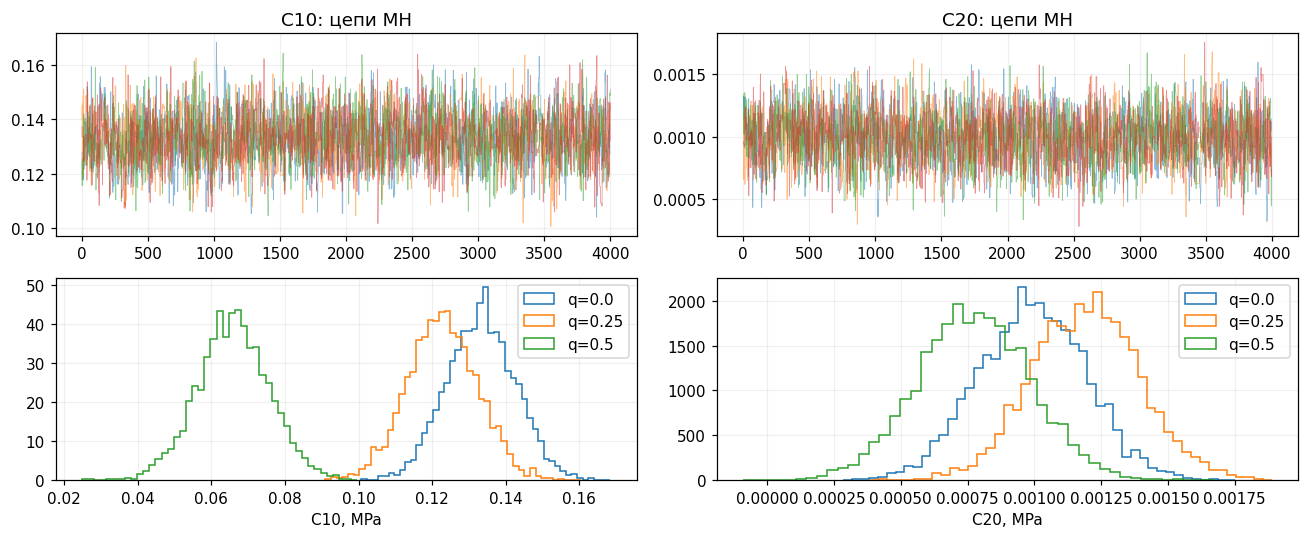

In [ ]:
def posterior(A,y,sd):
    p=A.shape[1];m=np.array([.2,0.])[:p];s=np.array([.3,.02])[:p]
    B=A/np.asarray(sd)[:,None];v=y/sd
    H=B.T@B+np.diag(1/s**2);cov=np.linalg.inv(H)
    return cov@(B.T@v+m/s**2),cov

def mh(mu,cov,seed):
    rng=np.random.default_rng(seed);p=len(mu);L=np.linalg.cholesky(cov)
    z=rng.normal(size=(4,p))*3;logp=-.5*(z*z).sum(1);saved=[];accepted=0
    # theta=mu+Lz: целевая плотность z стандартная нормальная.
    for i in range(5000):
        prop=z+rng.normal(size=z.shape)*(2.38/np.sqrt(p));lp=-.5*(prop*prop).sum(1)
        ok=np.log(rng.random(4))<lp-logp;z[ok]=prop[ok];logp[ok]=lp[ok]
        if i>=1000:saved.append(mu+z@L.T);accepted+=ok.sum()
    return np.transpose(saved,(1,0,2)),accepted/(4*4000)
def diagnostics(ch):
    m,n,p=ch.shape;a=np.concatenate([ch[:,:n//2],ch[:,n//2:]],axis=0);nn=a.shape[1]
    W=a.var(1,ddof=1).mean(0);B=nn*a.mean(1).var(0,ddof=1)
    rhat=np.sqrt(((nn-1)/nn*W+B/nn)/W);ess=[]
    for j in range(p):
        z=ch[:,:,j]-ch[:,:,j].mean(1,keepdims=True)
        ft=np.fft.rfft(z,n=2*n,axis=1);ac=np.fft.irfft(ft*ft.conj(),axis=1)[:,:n].real
        ac=(ac/ac[:,0,None]).mean(0);pairs=ac[1:1001].reshape(-1,2).sum(1)
        cut=np.where(pairs<0)[0];pairs=pairs[:cut[0]] if len(cut) else pairs
        ess.append(m*n/max(1,1+2*pairs.sum()))
    return rhat,np.array(ess)
results={};rows=[]
for j,(name,(x,y,sig)) in enumerate(datasets.items()):
    tr,te=splits[name];A=design(x[tr])
    for q in [0.,.25,.5]:
        yy=y[tr].copy();yy[masks[name][:int(q*len(yy))]]=0
        mu,cov=posterior(A,yy,np.full(len(yy),sig));ch,acc=mh(mu,cov,100+j*10+int(q*4))
        results[name,q]=(mu,cov,ch,yy)
        rh,es=diagnostics(ch)
        rows.append([name,q,acc,rh.max(),es.min(),np.max(abs(ch.mean((0,1))-mu)/np.sqrt(np.diag(cov)))])
diag=pd.DataFrame(rows,columns=['Данные','q','Принятие','max Rhat','min ESS','Ошибка среднего / SD'])
print(diag.round(4).to_string(index=False))
assert diag['max Rhat'].max()<1.05
fig,axs=plt.subplots(2,2,figsize=(12,5))
ch=results['Treloar',0][2]
for j in range(2):
    axs[0,j].plot(ch[:,:,j].T,alpha=.5,lw=.5);axs[0,j].set_title(['C10','C20'][j]+': цепи MH')
    for q in [0.,.25,.5]:axs[1,j].hist(results['Treloar',q][2][:,:,j].ravel(),bins=45,density=True,histtype='step',label=f'q={q}')
    axs[1,j].legend();axs[1,j].set_xlabel(['C10, MPa','C20, MPa'][j])
plt.tight_layout();plt.show()


## 4. Колмогоров — Смирнов: расстояние и проверка гипотезы
Статистика D = sup|F₀−Fq| измеряет максимальное отличие эмпирических CDF. Нулевая гипотеза: маргинальные распределения параметра совпадают. D рассчитываем непосредственно на MH-выборках.

Обычный p-value KS требует независимых наблюдений. Поэтому **не используем его для зависимых состояний MH**. Для формального теста берём по 500 независимых выборок из точных нормальных posterior той же задачи и считаем KS с p-value. Это отдельная проверка тех же распределений, доступная благодаря простоте модели. Поправка Бонферрони применяется ко всем 12 тестам (3 набора × 2 ненулевых q × 2 параметра). Значимость не является критерием удаления ветви. При q=0 расстояние между одной и той же выборкой равно нулю по определению.

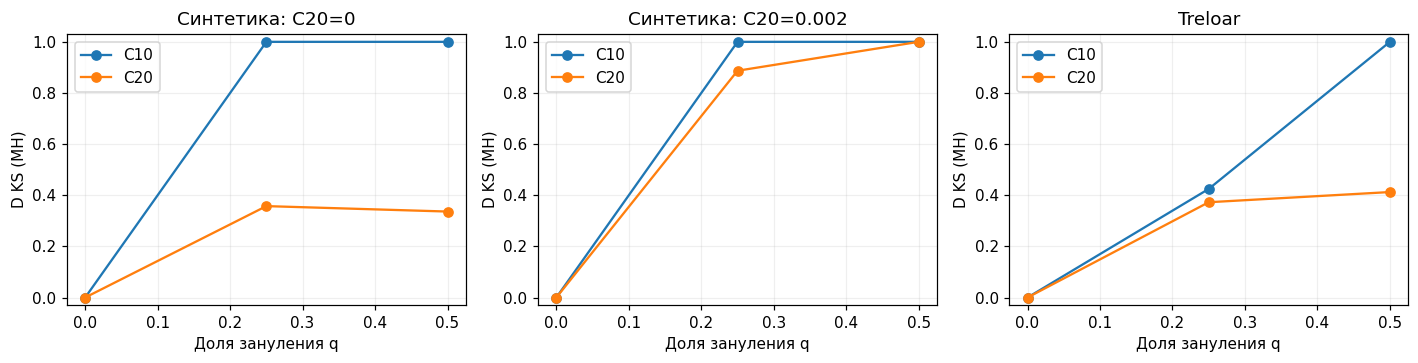

              Данные    q Параметр   D MH  D iid      p iid  p Bonferroni
    Синтетика: C20=0 0.25      C10      1      1   7.4e-300    8.879e-299
    Синтетика: C20=0  0.5      C10      1      1   7.4e-300    8.879e-299
    Синтетика: C20=0 0.25      C20 0.3575  0.396  2.162e-35     2.594e-34
    Синтетика: C20=0  0.5      C20 0.3362  0.392  1.142e-34      1.37e-33
Синтетика: C20=0.002 0.25      C10      1      1   7.4e-300    8.879e-299
Синтетика: C20=0.002  0.5      C10      1      1   7.4e-300    8.879e-299
Синтетика: C20=0.002 0.25      C20 0.8869  0.894 4.257e-211    5.108e-210
Синтетика: C20=0.002  0.5      C20      1      1   7.4e-300    8.879e-299
             Treloar 0.25      C10 0.4246  0.434  1.131e-42     1.357e-41
             Treloar  0.5      C10      1      1   7.4e-300    8.879e-299
             Treloar 0.25      C20 0.3727  0.394  4.981e-35     5.977e-34
             Treloar  0.5      C20 0.4125  0.412  2.297e-38     2.756e-37


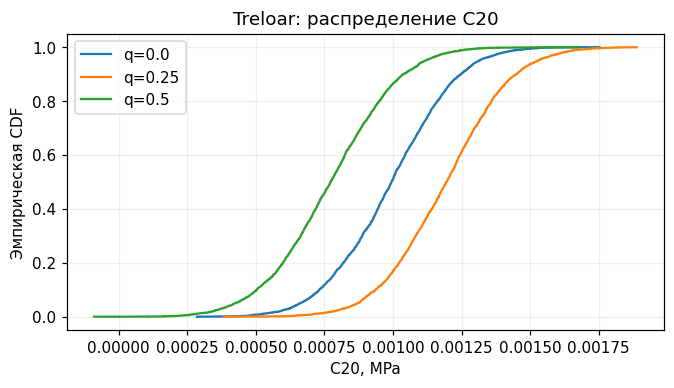

In [ ]:
ksrows=[];rng=np.random.default_rng(805)
fig,axs=plt.subplots(1,3,figsize=(13,3.4))
for ax,name in zip(axs,datasets):
    for j,label in enumerate(['C10','C20']):
        ds=[0.]
        for q in [.25,.5]:
            m0,c0,ch0,_=results[name,0];m1,c1,ch1,_=results[name,q]
            D=stats.ks_2samp(ch0[:,:,j].ravel(),ch1[:,:,j].ravel()).statistic
            independent=stats.ks_2samp(rng.normal(m0[j],np.sqrt(c0[j,j]),500),rng.normal(m1[j],np.sqrt(c1[j,j]),500))
            ksrows.append([name,q,label,D,independent.statistic,independent.pvalue,min(1,12*independent.pvalue)])
            ds.append(D)
        ax.plot([0,.25,.5],ds,'o-',label=label)
    ax.set(title=name,xlabel='Доля зануления q',ylabel='D KS (MH)',ylim=(-.03,1.03));ax.legend()
plt.tight_layout();plt.show()
ks=pd.DataFrame(ksrows,columns=['Данные','q','Параметр','D MH','D iid','p iid','p Bonferroni'])
print(ks.to_string(index=False,float_format=lambda x:f'{x:.4g}'))
fig,ax=plt.subplots(figsize=(7,3.5))
for q in [0.,.25,.5]:
    a=np.sort(results['Treloar',q][2][:,:,1].ravel());ax.plot(a,np.arange(1,len(a)+1)/len(a),label=f'q={q}')
ax.set(xlabel='C20, MPa',ylabel='Эмпирическая CDF',title='Treloar: распределение C20');ax.legend();plt.show()


## 5. Решение об удалении ветви
Интервенция показывает чувствительность параметров, но не доказывает ненужность члена. Проверяем сокращённый граф на **исходных**, не занулённых данных. Заранее фиксируем учебное правило: удалить C20, если его 95% credible interval содержит ноль и проверочная RMSE увеличилась не более чем на 0.02 MPa (не универсальная константа). Дополнительно требуем C10>0 и положительную касательную dP/dλ на λ∈[1,6] у выбранного среднего закона. Это локальная проверка, не доказательство глобальной устойчивости.


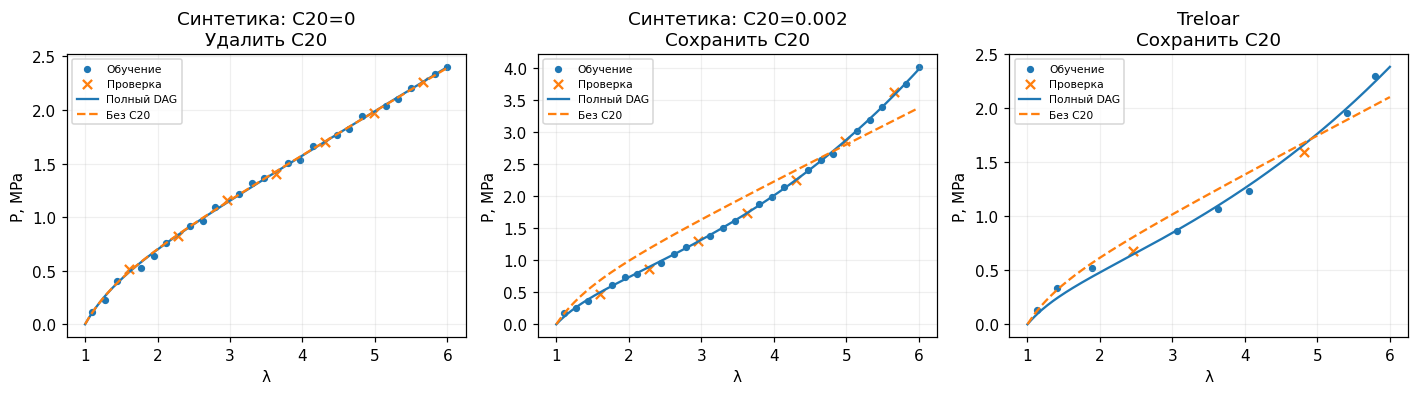

              Данные     C20 low   C20 high  RMSE полный  RMSE сокращённый      Δ RMSE       Решение
    Синтетика: C20=0 -6.0558e-05 0.00011661     0.018093          0.017962 -0.00013154   Удалить C20
Синтетика: C20=0.002   0.0018788  0.0020515     0.025525           0.27731     0.25179 Сохранить C20
             Treloar  0.00059913  0.0013831     0.055111           0.10705    0.051941 Сохранить C20
Выводы по выполненному запуску:
• Синтетика: C20=0: Удалить C20; изменение RMSE = -0.0001 MPa.
• Синтетика: C20=0.002: Сохранить C20; изменение RMSE = 0.2518 MPa.
• Treloar: Сохранить C20; изменение RMSE = 0.0519 MPa.
• Значимые различия после поправки: 12 из 12 сравнений.
• Время вычислений и построения рисунков: 7.6 с.


In [ ]:
decisions=[];fig,axs=plt.subplots(1,3,figsize=(13,3.7))
for i,(ax,(name,(x,y,sig))) in enumerate(zip(axs,datasets.items())):
    tr,te=splits[name];mu,cov,ch,_=results[name,0]
    m1,c1=posterior(design(x[tr],True),y[tr],np.full(tr.sum(),sig));csmall,_=mh(m1,c1,700+i)
    t=ch.mean((0,1));t1=csmall.mean((0,1))
    err=lambda p:np.sqrt(np.mean((p-y[te])**2))
    ef=err(design(x[te])@t);er=err(design(x[te],True)@t1)
    lo,hi=np.quantile(ch[:,:,1],[.025,.975]);remove=lo<=0<=hi and er-ef<=.02
    grid=np.linspace(1,6,200);chosen=design(grid,remove)@(t1 if remove else t)
    physical=(t1[0] if remove else t[0])>0 and np.all(np.diff(chosen)>0)
    decision=('Удалить C20' if remove else 'Сохранить C20') if physical else 'Нет физически допустимого решения'
    decisions.append([name,lo,hi,ef,er,er-ef,decision])
    ax.scatter(x[tr],y[tr],s=14,label='Обучение');ax.scatter(x[te],y[te],marker='x',label='Проверка')
    ax.plot(grid,design(grid)@t,label='Полный DAG');ax.plot(grid,design(grid,True)@t1,'--',label='Без C20')
    ax.set(title=name+'\n'+decision,xlabel='λ',ylabel='P, MPa');ax.legend(fontsize=7)
plt.tight_layout();plt.show()
summary=pd.DataFrame(decisions,columns=['Данные','C20 low','C20 high','RMSE полный','RMSE сокращённый','Δ RMSE','Решение'])
print(summary.to_string(index=False,float_format=lambda v:f'{v:.5g}'))
print('Выводы по выполненному запуску:')
for row in decisions: print(f'• {row[0]}: {row[-1]}; изменение RMSE = {row[5]:.4f} MPa.')
print(f'• Значимые различия после поправки: {(ks["p Bonferroni"]<.05).sum()} из {len(ks)} сравнений.')
print(f'• Время вычислений и построения рисунков: {time.perf_counter()-START:.1f} с.')


## 6. Обсуждение
1. Мы работаем с вычислительным графом энергии: удаление C20 отключает конкретное слагаемое, а вычисление напряжения проходит через производные операций DAG.
2. В синтетике известна структура. Контроль с C20=0 проверяет возможность удаления; второй контроль — сохранение нужной нелинейной ветви.
3. Зануление не эквивалентно удалению строки: оно сообщает модели «при этой деформации напряжение равно нулю» и меняет posterior. На реальных данных это моделирует повреждение измерений.
4. MH даёт выборки параметров, а не только оптимум. Аналитический posterior позволяет проверить корректность семплера на небольшой задаче.
5. KS измеряет изменение CDF. Малый p-value означает различие распределений в принятой вероятностной модели, а не необходимость удалить параметр. Для p-value использованы независимые контрольные выборки; для MH — статистика D.
6. Решение о ветви подтверждается повторной идентификацией сокращённого графа и качеством на отложенных исходных наблюдениях. Для Treloar неизвестен «истинный порядок Yeoh»; вывод относится к диапазону λ≤6 и выбранному допуску.

**Ограничения:** одноосный однородный случай, одна маска зануления, фиксированный масштаб ошибки, нормальный prior без жёстких физических ограничений. Интервенционные posterior могут включать нефизические коэффициенты: это результат повреждения данных. Одномерные KS не проверяют совместное распределение. Сходимость не заменяет проверку адекватности модели. Пространственная PDE и объёмная ветвь остаются за рамками этой компактной работы.

## Источники
1. Treloar L.R.G. (1944). Stress-strain data for vulcanised rubber under various types of deformation. Trans. Faraday Soc. 40, 59–70. https://doi.org/10.1039/TF9444000059
2. Linka K., Kuhl E. (2023). A new family of Constitutive Artificial Neural Networks towards automated model discovery. CMAME 403, 115731. https://doi.org/10.1016/j.cma.2022.115731 — источник цифровых данных CANN (точная версия указана выше).
3. Yeoh O.H. (1993). Some forms of the strain energy function for rubber. Rubber Chemistry and Technology 66, 754–771. https://doi.org/10.5254/1.3538343
4. Hastings W.K. (1970). Monte Carlo sampling methods using Markov chains and their applications. Biometrika 57, 97–109. https://doi.org/10.1093/biomet/57.1.97
5. SciPy: двухвыборочный критерий Колмогорова — Смирнова и предпосылки независимости. https://docs.scipy.org/doc/scipy/reference/generated/scipy.stats.ks_2samp.html
6. Vehtari et al. (2021). Rank-normalization, folding, and localization: an improved R-hat. https://arxiv.org/abs/1903.08008 — современные диагностики; здесь использован более простой split-Rhat для нормальной цели.

